# Лабораторная работа №2, вариант 7

## Подготовка

In [2]:
import csv
import io
import os
import platform
from pathlib import Path

lab = Path("/home/denis/Desktop/VMK/cuda-course/lab2-variant7")
os.chdir(lab)
report = lab / "report"
work = report / "work"
work.mkdir(exist_ok=True)
os.environ["TMPDIR"] = str(work)

import subprocess
def run(args, input=None):
    result = subprocess.run([str(arg) for arg in args], input=input, capture_output=True, text=True, timeout=1800)
    if result.returncode or "ERROR:" in result.stderr:
        raise RuntimeError(result.stderr or result.stdout)
    return result.stdout

nvcc = "/usr/local/cuda-12.8/bin/nvcc"

02.data → 02.png


57.data → 57.png


95.data → 95.png


96.data → 96.png


97.data → 97.png


98.data → 98.png


99.data → 99.png


color-gradient.data → color-gradient.png


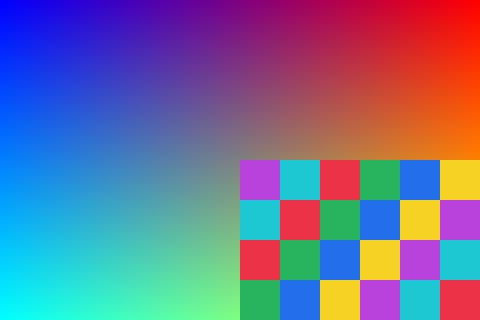

color-shapes.data → color-shapes.png


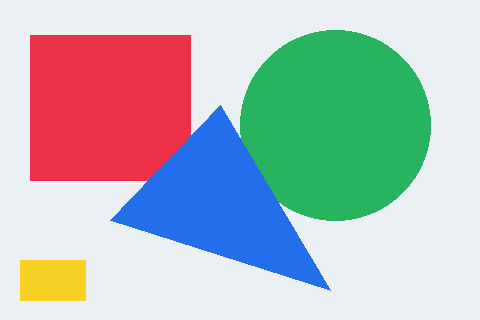

color-stripes.data → color-stripes.png


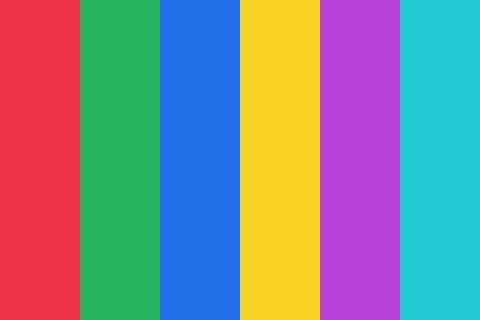

In [3]:
from convert import convert
from PIL import Image as PillowImage
from IPython.display import Image, display

work.mkdir(exist_ok=True)
files = sorted((lab / "data").glob("*.data"))
assert files, "В папке data нет файлов .data"

for source in files:
    target = work / (source.stem + ".png")
    convert("to-png", source, target)
    print(source.name, "→", target.name)
    with PillowImage.open(target) as picture:
        width, height = picture.size
    scale = max(1, 160 // max(width, height))
    display(Image(data=target.read_bytes(), width=width * scale, height=height * scale))


## Компиляция

In [4]:
run([nvcc, "-O2", "-std=c++17", "-arch=sm_61", lab / "lab2.cu", "-o", lab / "lab2"])
run([nvcc, "-O2", "-std=c++17", "-arch=sm_61", report / "benchmark.cu", "-o", report / "benchmark"])
run(["g++", "-O2", "-std=c++17", report / "cpu.cpp", "-o", report / "cpu"])
print("Программы собраны.")

Программы собраны.


## Компьютер и программы

In [5]:
print("ОС:", platform.platform())
print("Python:", platform.python_version())
print("Логических процессоров:", os.cpu_count())
for line in Path("/proc/cpuinfo").read_text().splitlines():
    if line.startswith("model name"):
        print("CPU:", line.split(":", 1)[1].strip())
        break
print("RAM:", Path("/proc/meminfo").read_text().splitlines()[0])
print(run(["lsblk", "-d", "-e", "7", "-o", "NAME,MODEL,SIZE"]))

ОС: Linux-6.8.0-138-generic-x86_64-with-glibc2.35
Python: 3.10.12
Логических процессоров: 12
CPU: Intel(R) Core(TM) i7-9750H CPU @ 2.60GHz
RAM: MemTotal:       16250044 kB
NAME    MODEL                SIZE
sda     WDC WD10SPZX-24Z10 931,5G
nvme0n1 HFM256GDHTNG-8310A 238,5G



In [6]:
print(run([report / "benchmark", "--info"]))
print(run([nvcc, "--version"]))
print(run(["g++", "--version"]).splitlines()[0])

name,NVIDIA GeForce GTX 1050
compute_capability,6.1
global_memory_bytes,3158114304
shared_memory_per_block_bytes,49152
constant_memory_bytes,65536
registers_per_block,65536
max_threads_per_block,1024
max_threads_dimensions,1024x1024x64
max_grid_dimensions,2147483647x65535x65535
multiprocessors,6

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Fri_Feb_21_20:23:50_PST_2025
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0

g++ (Ubuntu 11.4.0-1ubuntu1~22.04.3) 11.4.0


## Измерения

Размеры: 32×32, 1024×1024 и 10000×10000.
Проверяем семь конфигураций сетки. После прогрева усредняем 100 запусков
для каждого размера. CPU измеряется через chrono, GPU — через CUDA events.
Время чтения, записи, выделения и копирования памяти не учитывается.
Ускорение = время CPU / время GPU. Результаты сравниваются с точностью ±1.

In [7]:
measurements = []
for size in [32, 1024, 10000]:
    print("Размер:", size, "x", size, flush=True)
    text = run([report / "benchmark", str(size), str(size)])
    rows = list(csv.DictReader(io.StringIO(text)))
    assert len(rows) == 7
    measurements.extend(rows)

Размер: 32 x 32
Размер: 1024 x 1024
Размер: 10000 x 10000


In [8]:
print("Размер       Конфигурация       CPU, мс      GPU, мс    Ускорение  Ошибка")
for row in measurements:
    size = row["width"] + "x" + row["height"]
    config = "<<<" + row["blocks"] + "," + row["threads"] + ">>>"
    cpu = float(row["cpu_ms"])
    gpu = float(row["gpu_ms"])
    speedup = float(row["speedup"])
    print(f'{size:12} {config:18} {cpu:10.4f} {gpu:10.4f} {speedup:9.2f} {row["max_error"]:>7}')

Размер       Конфигурация       CPU, мс      GPU, мс    Ускорение  Ошибка
32x32        <<<1,32>>>             0.0483     0.0218      2.21       0
32x32        <<<16,64>>>            0.0483     0.0043     11.30       0
32x32        <<<64,256>>>           0.0483     0.0066      7.35       0
32x32        <<<256,256>>>          0.0483     0.0064      7.55       0
32x32        <<<1024,256>>>         0.0483     0.0112      4.32       0
32x32        <<<1024,512>>>         0.0483     0.0209      2.31       0
32x32        <<<1024,1024>>>        0.0483     0.0608      0.79       0
1024x1024    <<<1,32>>>            49.9736    14.4722      3.45       0
1024x1024    <<<16,64>>>           49.9736     0.5197     96.16       0
1024x1024    <<<64,256>>>          49.9736     0.1645    303.83       0
1024x1024    <<<256,256>>>         49.9736     0.1610    310.46       0
1024x1024    <<<1024,256>>>        49.9736     0.1549    322.64       0
1024x1024    <<<1024,512>>>        49.9736     0.1881    265.6

## Проверка CPU и GPU

Проверяем файлы из папки data, включая три цветных изображения.

In [9]:
inputs = sorted((lab / "data").glob("*.data"))
for source in inputs:
    gpu_file = work / (source.stem + ".gpu.data")
    cpu_file = work / (source.stem + ".cpu.data")
    run([lab / "lab2"], input=f"{source}\n{gpu_file}\n")
    run([report / "cpu"], input=f"{source}\n{cpu_file}\n")

    gpu = gpu_file.read_bytes()
    cpu = cpu_file.read_bytes()
    assert gpu[:8] == cpu[:8] and len(gpu) == len(cpu)
    error = max(abs(a - b) for a, b in zip(gpu[8:], cpu[8:]))
    assert error <= 1
    assert all(alpha == 0 for alpha in gpu[11::4])
    print(source.name, "— ошибка:", error)

02.data — ошибка: 0
57.data — ошибка: 0
95.data — ошибка: 0
96.data — ошибка: 0
97.data — ошибка: 0
98.data — ошибка: 0
99.data — ошибка: 0
color-gradient.data — ошибка: 0
color-shapes.data — ошибка: 0
color-stripes.data — ошибка: 0


## Изображения до и после

Семь изображений из условия и три цветных примера. Для каждого показаны исходное и результат Собеля.


02.data — исходное


Результат Собеля


57.data — исходное


Результат Собеля


95.data — исходное


Результат Собеля


96.data — исходное


Результат Собеля


97.data — исходное


Результат Собеля


98.data — исходное


Результат Собеля


99.data — исходное


Результат Собеля


color-gradient.data — исходное


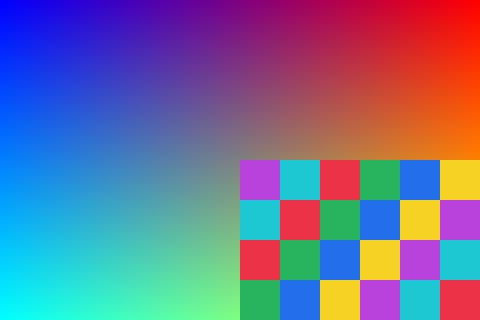

Результат Собеля


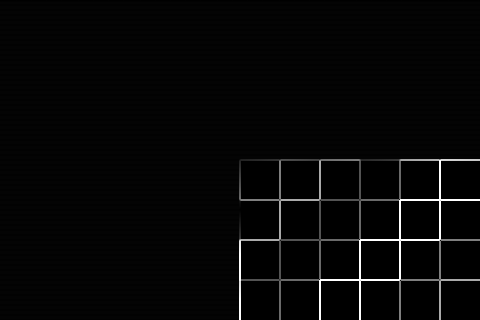

color-shapes.data — исходное


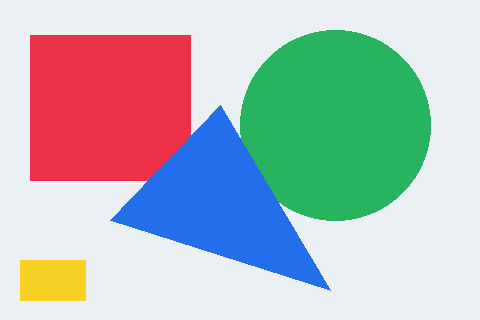

Результат Собеля


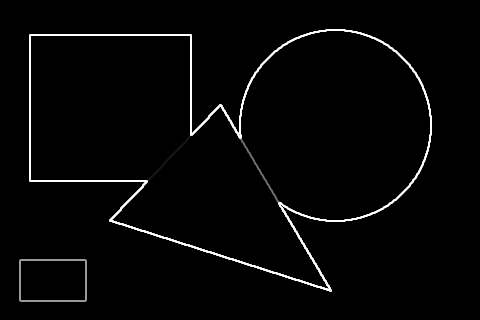

color-stripes.data — исходное


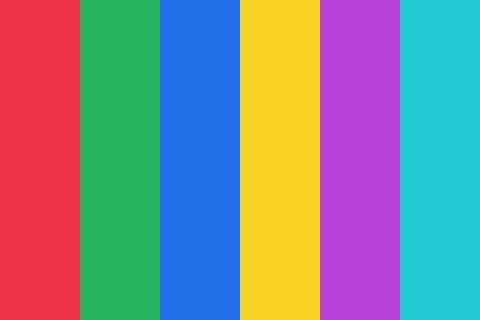

Результат Собеля


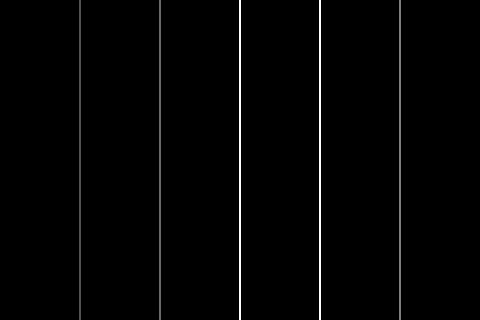

In [10]:
for source in sorted((lab / "data").glob("*.data")):
    result = work / (source.stem + ".gpu.data")
    original_png = work / (source.stem + "-original.png")
    result_png = work / (source.stem + "-sobel.png")
    convert("to-png", source, original_png)
    convert("to-png", result, result_png)
    with PillowImage.open(original_png) as picture:
        width, height = picture.size
    scale = max(1, 160 // max(width, height))
    print(source.name, "— исходное")
    display(Image(filename=str(original_png), width=width * scale, height=height * scale))
    print("Результат Собеля")
    display(Image(filename=str(result_png), width=width * scale, height=height * scale))


## Выводы

Выбираем самую быструю из проверенных конфигураций для каждого размера.

In [11]:
for size in [32, 1024, 10000]:
    rows = []
    for row in measurements:
        if int(row["width"]) == size:
            rows.append(row)
    best = min(rows, key=lambda row: float(row["gpu_ms"]))
    print("Размер изображения:", size, "x", size)
    print("Конфигурация: <<<" + best["blocks"] + "," + best["threads"] + ">>>")
    print("GPU, мс:", best["gpu_ms"], "Ускорение:", best["speedup"])
    print()

Размер изображения: 32 x 32
Конфигурация: <<<16,64>>>
GPU, мс: 0.00428000002 Ускорение: 11.2951378

Размер изображения: 1024 x 1024
Конфигурация: <<<1024,256>>>
GPU, мс: 0.154889921 Ускорение: 322.639726

Размер изображения: 10000 x 10000
Конфигурация: <<<1024,512>>>
GPU, мс: 15.6793699 Ускорение: 293.611115



Результаты показали высокую эффективность GPU для обработки изображений: на размерах 1024×1024 и 10000×10000 лучшие конфигурации ускорили вычисления примерно в 323 и 294 раза относительно CPU. Три цветных примера, добавленные к семи изображениям из условия, нагляднее показывают работу метода Собеля на границах фигур, цветных полосах и плавных переходах. На всех проверенных изображениях ошибок и расхождений между CPU и GPU при вычислении результата алгоритма не обнаружено.